# Klasifikasi Tutupan Lahan Jawa Timur — Random Forest

Notebook lokal untuk membaca 350 sampel GeoJSON, mengekstrak enam band Sentinel-2 hasil clipping, melatih Random Forest, lalu menghasilkan peta interaktif Folium.

Letakkan notebook di folder proyek yang sama dengan `jawa_timur.geojson`, `lokasi.geojson` (opsional), dan folder `hasil_clip/` berisi `B02_clip.tif`, `B03_clip.tif`, `B04_clip.tif`, `B08_clip.tif`, `B8A_clip.tif`, `B11_clip.tif`.


## 1. Import pustaka dan atur lokasi file

Cell ini memuat pustaka untuk membaca GeoJSON dan raster, membangun model Random Forest, mengevaluasi hasil, serta membuat peta interaktif.

In [4]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image
import folium
from folium.raster_layers import ImageOverlay
warnings.filterwarnings("ignore", category=UserWarning)

BASE = Path.cwd()
SAMPLE_FILE = BASE / "jawaTimur.geojson"
RASTER_DIR = BASE / "jawa_timur"
BOUNDARY_FILE = BASE / "lokasi.geojson"
BANDS = ["B02", "B03", "B04", "B08", "B8A", "B11"]
RASTER_FILES = {b: RASTER_DIR / f"{b}_clip.tif" for b in BANDS}

print("Folder kerja:", BASE)
print("Sampel ditemukan:", SAMPLE_FILE.exists())
for b, p in RASTER_FILES.items():
    print(b, p.exists(), p)


Folder kerja: c:\Users\LENOVO\PSD\pertemuan_6
Sampel ditemukan: True
B02 False c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B02_clip.tif
B03 False c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B03_clip.tif
B04 False c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B04_clip.tif
B08 False c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B08_clip.tif
B8A False c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B8A_clip.tif
B11 False c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B11_clip.tif


## 2. Membaca data sampel

Baca `jawa_timur.geojson`, periksa jumlah fitur, CRS, jenis geometri, kolom atribut, dan nilai kolom yang berpotensi menjadi label kelas.

In [5]:
# Baca sampel dan deteksi kolom label
if not SAMPLE_FILE.exists():
    raise FileNotFoundError(f"Tidak menemukan {SAMPLE_FILE}. Letakkan jawa_timur.geojson di folder notebook.")

samples = gpd.read_file(SAMPLE_FILE)
print("Jumlah fitur:", len(samples))
print("CRS:", samples.crs)
print("Kolom:", samples.columns.tolist())
print("Geometri:", samples.geometry.geom_type.value_counts().to_dict())
display(samples.drop(columns="geometry").head())

candidate_cols = [
    "class_name", "kelas", "class", "label", "nama_kelas",
    "tutupan_lahan", "landcover", "jenis", "nama", "kategori", "original_category"
]
label_col = next((c for c in candidate_cols if c in samples.columns), None)
if label_col is None:
    raise ValueError("Kolom label kelas tidak terdeteksi. Kolom tersedia: " + str([c for c in samples.columns if c != samples.geometry.name]))
print("Kolom label terpilih:", label_col)
print(samples[label_col].value_counts(dropna=False))


Jumlah fitur: 350
CRS: EPSG:4326
Kolom: ['sample_id', 'class_name', 'class_id', 'source_file', 'source_index', 'original_category', 'geometry']
Geometri: {'Polygon': 348, 'MultiPolygon': 2}


,sample_id,class_name,class_id,source_file,source_index,original_category
0,1,Hutan,1,DATA_FINAL_UTS.geojson,1,hutan1
1,2,Hutan,1,DATA_FINAL_UTS.geojson,2,hutan2
2,3,Hutan,1,DATA_FINAL_UTS.geojson,3,hutan3
3,4,Hutan,1,DATA_FINAL_UTS.geojson,5,hutan5
4,5,Hutan,1,DATA_FINAL_UTS.geojson,6,hutan6


Kolom label terpilih: class_name
class_name
Hutan                    70
Perairan / Water body    70
Lahan pertanian          70
Bangunan                 70
Mangrove                 70
Name: count, dtype: int64


## 3. Menyamakan label menjadi lima kelas

Label sampel dipetakan ke kelas **Hutan, Perairan, Lahan pertanian, Bangunan, dan Mangrove**. Jika nama kelas dalam GeoJSON berbeda, sesuaikan kamus `CLASS_ALIASES`.

In [6]:

import geopandas as gpd
import pandas as pd
import numpy as np

# Baca ulang file sampel yang benar
SAMPLE_FILE = "jawaTimur.geojson"
samples = gpd.read_file(SAMPLE_FILE)

print("Jumlah fitur:", len(samples))
print("Nama kolom:", samples.columns.tolist())

# Cari kolom label secara otomatis
candidates = [
    "class_name", "kelas_rf", "kelas", "class",
    "label", "nama", "jenis", "kategori"
]
label_col = next(
    (c for c in candidates if c in samples.columns),
    None
)

if label_col is None:
    raise ValueError(
        "Kolom label tidak ditemukan. Kolom tersedia: "
        + str(samples.columns.tolist())
    )

print("Kolom label:", label_col)
print("\nLabel asli:")
print(samples[label_col].value_counts(dropna=False))

# Normalisasi teks: huruf kecil dan spasi bersih
def normalize_label(value):
    if pd.isna(value):
        return np.nan

    text = " ".join(str(value).strip().casefold().split())

    if "mangrove" in text:
        return "Mangrove"
    if "hutan" in text or "forest" in text:
        return "Hutan"
    if "perairan" in text or "water" in text or "badan air" in text:
        return "Perairan"
    if "pertanian" in text or "cropland" in text or "agriculture" in text:
        return "Lahan pertanian"
    if "bangunan" in text or "built-up" in text or "built up" in text:
        return "Bangunan"

    return np.nan

samples["kelas_rf"] = samples[label_col].apply(normalize_label)

print("\nHasil normalisasi:")
print(samples["kelas_rf"].value_counts(dropna=False))

TARGET_CLASSES = [
    "Hutan", "Perairan", "Lahan pertanian",
    "Bangunan", "Mangrove"
]

missing = sorted(
    set(TARGET_CLASSES) - set(samples["kelas_rf"].dropna().unique())
)

if missing:
    print("\nLabel yang belum dikenali:", missing)
    print("Periksa daftar label asli di atas.")
    raise ValueError("Normalisasi belum lengkap.")
else:
    print("\nBerhasil: semua lima kelas ditemukan.")


Jumlah fitur: 350
Nama kolom: ['sample_id', 'class_name', 'class_id', 'source_file', 'source_index', 'original_category', 'geometry']
Kolom label: class_name

Label asli:
class_name
Hutan                    70
Perairan / Water body    70
Lahan pertanian          70
Bangunan                 70
Mangrove                 70
Name: count, dtype: int64

Hasil normalisasi:
kelas_rf
Hutan              70
Perairan           70
Lahan pertanian    70
Bangunan           70
Mangrove           70
Name: count, dtype: int64

Berhasil: semua lima kelas ditemukan.


## 4. Memeriksa file raster

Pastikan keenam raster hasil clipping tersedia. Raster harus memiliki ukuran, CRS, dan transformasi grid yang sama agar piksel dari setiap band saling cocok.

In [7]:
missing_files = [str(p) for p in RASTER_FILES.values() if not p.exists()]
if missing_files:
    raise FileNotFoundError("Raster tidak ditemukan:\n" + "\n".join(missing_files))
print("Semua file raster ditemukan.")

FileNotFoundError: Raster tidak ditemukan:
c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B02_clip.tif
c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B03_clip.tif
c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B04_clip.tif
c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B08_clip.tif
c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B8A_clip.tif
c:\Users\LENOVO\PSD\pertemuan_6\jawa_timur\B11_clip.tif

## 5. Membaca dan menyusun band

Setiap band dibaca lalu digabungkan menjadi tumpukan data (*stack*) enam band. Piksel bernilai nol atau NoData dikeluarkan dari proses klasifikasi.

In [ ]:
srcs = {b: rasterio.open(p) for b, p in RASTER_FILES.items()}
reference = srcs["B02"]
profile = reference.profile.copy()
height, width = reference.height, reference.width
print("Dimensi:", width, "x", height, "| CRS:", reference.crs, "| bounds:", reference.bounds)

for b, src in srcs.items():
    if (src.width, src.height, src.transform, src.crs) != (reference.width, reference.height, reference.transform, reference.crs):
        raise ValueError(f"Raster {b} tidak berada pada grid yang sama dengan B02.")

stack = np.stack([srcs[b].read(1) for b in BANDS], axis=0)
valid_mask = np.all(np.isfinite(stack), axis=0) & np.all(stack != 0, axis=0)
for i, b in enumerate(BANDS):
    nd = srcs[b].nodata
    if nd is not None:
        valid_mask &= stack[i] != nd
print("Piksel valid:", int(valid_mask.sum()), "/", height * width)

Dimensi: 1243 x 738 | CRS: EPSG:4326 | bounds: BoundingBox(left=110.5482828224, bottom=-8.989606, right=114.694189, top=-6.548331555825243)
Piksel valid: 0 / 917334


## 6. Mengekstrak nilai band pada sampel

Titik sampel digunakan langsung. Untuk sampel berbentuk poligon, digunakan titik representatif. Nilai enam band pada lokasi tersebut menjadi fitur masukan model.

In [ ]:
from pathlib import Path
import rasterio
import numpy as np

folder = Path("hasil_clip")

print("Folder kerja:", Path.cwd())
print("Folder hasil_clip ditemukan:", folder.exists())

for nama in ["B02_clip.tif", "B03_clip.tif", "B04_clip.tif",
             "B08_clip.tif", "B8A_clip.tif", "B11_clip.tif"]:
    path = folder / nama
    print(f"\n--- {nama} ---")
    print("File ditemukan:", path.exists())

    if not path.exists():
        continue

    with rasterio.open(path) as src:
        arr = src.read(1, masked=True)
        valid = arr.compressed()

        print("CRS:", src.crs)
        print("Ukuran:", src.width, "x", src.height)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)
        print("Jumlah piksel valid:", valid.size)

        if valid.size:
            print("Min:", valid.min())
            print("Max:", valid.max())
            print("Jumlah nilai nonzero:", np.count_nonzero(valid))
        else:
            print("PERINGATAN: semua piksel terbaca sebagai NoData.")

Folder kerja: c:\Users\LENOVO\PSD\pertemuan_6
Folder hasil_clip ditemukan: True

--- B02_clip.tif ---
File ditemukan: True
CRS: EPSG:4326
Ukuran: 1243 x 738
Bounds: BoundingBox(left=110.5482828224, bottom=-8.989606, right=114.694189, top=-6.548331555825243)
NoData: 0.0
Jumlah piksel valid: 0
PERINGATAN: semua piksel terbaca sebagai NoData.

--- B03_clip.tif ---
File ditemukan: True
CRS: EPSG:4326
Ukuran: 1243 x 738
Bounds: BoundingBox(left=110.5482828224, bottom=-8.989606, right=114.694189, top=-6.548331555825243)
NoData: 0.0
Jumlah piksel valid: 0
PERINGATAN: semua piksel terbaca sebagai NoData.

--- B04_clip.tif ---
File ditemukan: True
CRS: EPSG:4326
Ukuran: 1243 x 738
Bounds: BoundingBox(left=110.5482828224, bottom=-8.989606, right=114.694189, top=-6.548331555825243)
NoData: 0.0
Jumlah piksel valid: 0
PERINGATAN: semua piksel terbaca sebagai NoData.

--- B08_clip.tif ---
File ditemukan: True
CRS: EPSG:4326
Ukuran: 1243 x 738
Bounds: BoundingBox(left=110.5482828224, bottom=-8.989606

## 7. Melatih dan mengevaluasi Random Forest

Data dibagi menjadi data latih dan data uji. Model dilatih dengan 300 pohon, lalu dievaluasi menggunakan akurasi, precision, recall, F1-score, dan confusion matrix.

In [ ]:
from pathlib import Path
import rasterio
import geopandas as gpd
import numpy as np

print("Folder kerja:", Path.cwd())

# Periksa raster
for nama in ["B02_clip.tif", "B03_clip.tif", "B04_clip.tif",
             "B08_clip.tif", "B8A_clip.tif", "B11_clip.tif"]:
    path = Path("hasil_clip") / nama
    print(f"\n--- {nama} ---")

    if not path.exists():
        print("FILE TIDAK DITEMUKAN:", path.resolve())
        continue

    with rasterio.open(path) as src:
        data = src.read(1)
        valid = data if src.nodata is None else data[data != src.nodata]

        print("CRS:", src.crs)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)
        print("Min raster:", np.min(data))
        print("Max raster:", np.max(data))
        print("Jumlah piksel nonzero:", np.count_nonzero(data))
        print("Jumlah piksel valid:", valid.size)

# Periksa file sampel
sampel_path = Path("jawaTimur.geojson")
print("\n--- FILE SAMPEL ---")
print("Path:", sampel_path.resolve())
print("Ditemukan:", sampel_path.exists())

if sampel_path.exists():
    sampel = gpd.read_file(sampel_path)
    print("Jumlah fitur:", len(sampel))
    print("CRS sampel:", sampel.crs)
    print("Kolom:", sampel.columns.tolist())
    print("Jenis geometri:", sampel.geom_type.value_counts().to_dict())
    print("Bounds sampel:", sampel.total_bounds)
    print(sampel.head(3))

Folder kerja: c:\Users\LENOVO\PSD\pertemuan_6

--- B02_clip.tif ---
CRS: EPSG:4326
Bounds: BoundingBox(left=110.5482828224, bottom=-8.989606, right=114.694189, top=-6.548331555825243)
NoData: 0.0
Min raster: 0
Max raster: 0
Jumlah piksel nonzero: 0
Jumlah piksel valid: 0

--- B03_clip.tif ---
CRS: EPSG:4326
Bounds: BoundingBox(left=110.5482828224, bottom=-8.989606, right=114.694189, top=-6.548331555825243)
NoData: 0.0
Min raster: 0
Max raster: 0
Jumlah piksel nonzero: 0
Jumlah piksel valid: 0

--- B04_clip.tif ---
CRS: EPSG:4326
Bounds: BoundingBox(left=110.5482828224, bottom=-8.989606, right=114.694189, top=-6.548331555825243)
NoData: 0.0
Min raster: 0
Max raster: 0
Jumlah piksel nonzero: 0
Jumlah piksel valid: 0

--- B08_clip.tif ---
CRS: EPSG:4326
Bounds: BoundingBox(left=110.5482828224, bottom=-8.989606, right=114.694189, top=-6.548331555825243)
NoData: 0.0
Min raster: 0
Max raster: 0
Jumlah piksel nonzero: 0
Jumlah piksel valid: 0

--- B8A_clip.tif ---
CRS: EPSG:4326
Bounds: Bound

## 8. Mengklasifikasikan seluruh piksel

Model terlatih memprediksi kelas pada setiap piksel valid. Prediksi dilakukan per batch agar penggunaan memori lebih terkendali. Nilai 0 menandakan NoData.

In [ ]:
# Prediksi seluruh piksel valid
class_to_id = {name: i + 1 for i, name in enumerate(TARGET_CLASSES)}
id_to_class = {v: k for k, v in class_to_id.items()}
pred_map = np.zeros((height, width), dtype=np.uint8)
rows, cols = np.where(valid_mask)
pixel_matrix = stack[:, rows, cols].T.astype(np.float32)
pred_ids = []
batch_size = 100_000
for start in range(0, len(pixel_matrix), batch_size):
    chunk_pred = model.predict(pixel_matrix[start:start + batch_size])
    pred_ids.extend(class_to_id[str(c)] for c in chunk_pred)
pred_map[rows, cols] = np.asarray(pred_ids, dtype=np.uint8)
print("Piksel terklasifikasi:", int((pred_map > 0).sum()))


Piksel terklasifikasi: 0


## 9. Menampilkan peta klasifikasi dan menyimpan GeoTIFF

Setiap kelas diberi warna yang berbeda. Hasil raster disimpan sebagai `hasil_klasifikasi_jatim.tif` agar bisa digunakan kembali di perangkat lunak GIS atau pemrosesan Python.

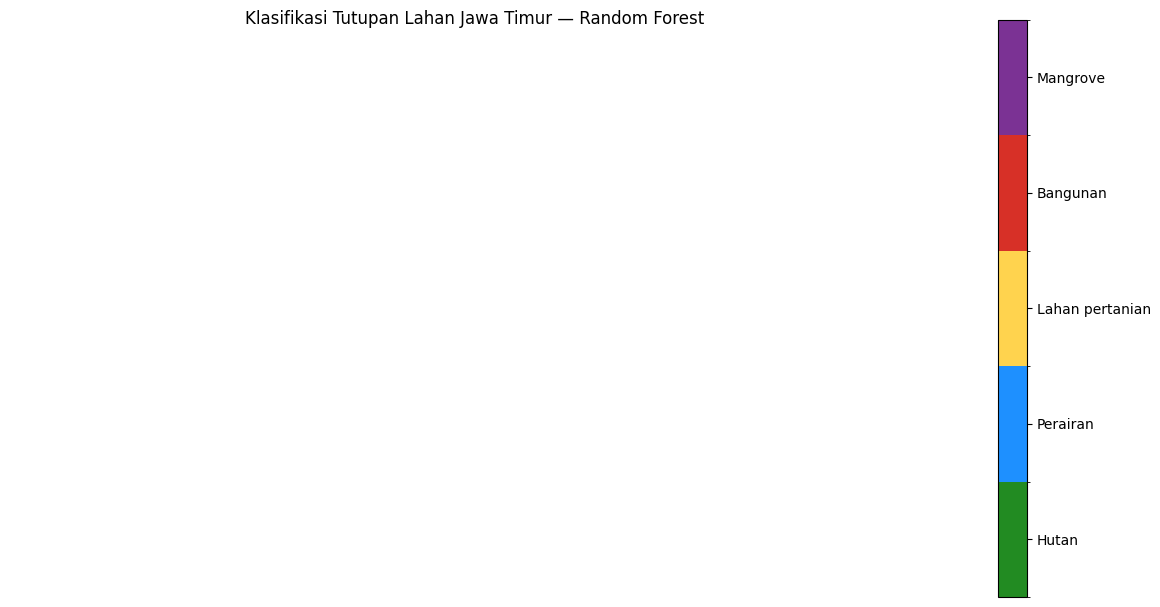

GeoTIFF tersimpan: c:\Users\LENOVO\PSD\pertemuan_6\hasil_klasifikasi_jatim.tif


In [ ]:
# Peta klasifikasi statis dan simpan GeoTIFF
colors = {
    "Hutan": "#228B22",
    "Perairan": "#1E90FF",
    "Lahan pertanian": "#FFD34E",
    "Bangunan": "#D73027",
    "Mangrove": "#7B3294"
}
cmap = mcolors.ListedColormap([colors[c] for c in TARGET_CLASSES])
norm = mcolors.BoundaryNorm(np.arange(0.5, len(TARGET_CLASSES) + 1.5, 1), cmap.N)
plt.figure(figsize=(12, 8))
plt.imshow(np.ma.masked_where(pred_map == 0, pred_map), cmap=cmap, norm=norm)
cb = plt.colorbar(ticks=np.arange(1, len(TARGET_CLASSES) + 1), shrink=0.75)
cb.ax.set_yticklabels(TARGET_CLASSES)
plt.title("Klasifikasi Tutupan Lahan Jawa Timur — Random Forest")
plt.axis("off")
plt.tight_layout()
plt.show()

out_tif = BASE / "hasil_klasifikasi_jatim.tif"
out_profile = profile.copy()
out_profile.update(count=1, dtype="uint8", nodata=0, compress="lzw")
with rasterio.open(out_tif, "w", **out_profile) as dst:
    dst.write(pred_map, 1)
print("GeoTIFF tersimpan:", out_tif)


## 10. Membuat overlay transparan

Raster klasifikasi diubah menjadi PNG RGBA agar dapat ditumpangkan di atas peta dasar web dengan area NoData tetap transparan.

In [ ]:
# Buat PNG transparan untuk overlay peta web
rgba = np.zeros((height, width, 4), dtype=np.uint8)
hex_to_rgb = {k: tuple(int(v[i:i+2], 16) for i in (1, 3, 5)) for k, v in colors.items()}
for class_name, class_id in class_to_id.items():
    mask = pred_map == class_id
    rgba[mask, :3] = hex_to_rgb[colors[class_name]]
    rgba[mask, 3] = 220
png_path = BASE / "overlay_klasifikasi_jatim.png"
Image.fromarray(rgba, mode="RGBA").save(png_path)
bounds = reference.bounds
image_bounds = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]
print("Overlay PNG:", png_path)


KeyError: '#228B22'

## 11. Membuat peta interaktif

Peta menggunakan Folium dengan pilihan basemap OpenStreetMap dan citra satelit, overlay hasil klasifikasi, batas wilayah (jika tersedia), legenda, serta kontrol layer. File HTML dapat dibuka di browser.

In [ ]:
# Peta interaktif Folium: basemap, overlay klasifikasi, batas, legenda
center = [(bounds.bottom + bounds.top) / 2, (bounds.left + bounds.right) / 2]
m = folium.Map(location=center, zoom_start=7, tiles=None, control_scale=True)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", overlay=False).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Citra satelit", overlay=False
).add_to(m)
ImageOverlay(
    name="Klasifikasi tutupan lahan",
    image=str(png_path),
    bounds=image_bounds,
    opacity=0.85,
    interactive=True,
    cross_origin=False,
    zindex=2
).add_to(m)

if BOUNDARY_FILE.exists():
    try:
        boundary = gpd.read_file(BOUNDARY_FILE)
        if boundary.crs is not None:
            boundary = boundary.to_crs("EPSG:4326")
        folium.GeoJson(
            boundary, name="Batas wilayah",
            style_function=lambda feature: {"color": "#111111", "weight": 1.5, "fillOpacity": 0},
            tooltip="Batas wilayah"
        ).add_to(m)
    except Exception as e:
        print("Batas wilayah tidak ditambahkan:", e)

legend_html = '''
<div style="position: fixed; bottom: 35px; left: 35px; z-index: 9999;
background: white; padding: 12px 14px; border: 1px solid #777;
border-radius: 5px; font-size: 13px; box-shadow: 0 1px 5px #777;">
<b>Klasifikasi Tutupan Lahan</b><br>
'''
for name in TARGET_CLASSES:
    legend_html += (
        f'<div style="margin-top:4px;">'
        f'<span style="display:inline-block;width:12px;height:12px;'
        f'background:{colors[name]};margin-right:7px;border:1px solid #555;"></span>'
        f'{name}</div>'
    )
legend_html += '</div>'
m.get_root().html.add_child(folium.Element(legend_html))
folium.LayerControl(collapsed=False).add_to(m)
html_path = BASE / "peta_klasifikasi_jatim.html"
m.save(str(html_path))
print("Peta interaktif tersimpan:", html_path)
m


NameError: name 'png_path' is not defined

## Output
- `peta_klasifikasi_jatim.html`: peta interaktif untuk dibuka di browser.
- `hasil_klasifikasi_jatim.tif`: raster hasil klasifikasi.
- `overlay_klasifikasi_jatim.png`: gambar transparan yang dipakai oleh peta web.

Jika sel normalisasi berhenti karena ada kelas yang tidak ditemukan, cocokkan `CLASS_ALIASES` dengan nilai label yang tampil pada sel pemeriksaan sampel. Kinerja klasifikasi bergantung pada ketepatan label sampel dan cakupan citra.
